# Random Forest - NIDS (CIC-UNSW-NB15-2024)

Random Forest classifier on the CIC-UNSW-NB15-2024 dataset. Uses the **same leakage-safe pipeline** as `decision_tree.ipynb` (dedupe -> evidence-based feature selection -> stratified split) so results are directly comparable.

**Decision Tree baseline to beat:** accuracy 0.8855, macro-F1 0.5338.

## 1. Data Collection
_Sources & Quality_

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Features and labels are two parallel files, row-aligned by position (no shared key).
X = pd.read_csv("Resource/CIC-UNSW-Data.csv")
y = pd.read_csv("Resource/CIC-UNSW-Label.csv")

print("Features:", X.shape)
print("Labels:  ", y.shape)
print("Rows aligned:", len(X) == len(y))
X.head()

Features: (447915, 76)
Labels:   (447915, 1)
Rows aligned: True


,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,...,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,214392,9,21,388.0,24564.0,194.0,0.0,43.111111,85.545959,1460.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2376792,9,3,752.0,0.0,188.0,0.0,83.555556,99.084700,0.0,...,4,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,131350,10,3,7564.0,0.0,1460.0,0.0,756.400000,690.497277,0.0,...,6,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,164796,6,3,770.0,0.0,385.0,0.0,128.333333,198.813145,0.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,163418,6,3,400.0,0.0,200.0,0.0,66.666667,103.279556,0.0,...,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## 2. Data Preparation
_Clean & Transform_

### 2.1 Check for duplicates

In [2]:
# Check duplicates on features + label together, so we only count rows that are
# truly identical (same flow AND same class).
df = pd.concat([X, y], axis=1)

n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
print(f"Duplicate share: {n_dup / len(df) * 100:.2f}%")

Duplicate rows: 141742
Duplicate share: 31.64%


### 2.2 Drop duplicates

In [3]:
# Drop on the combined frame so features and labels stay aligned, then split back.
df = df.drop_duplicates().reset_index(drop=True)

X = df[X.columns]
y = df[y.columns]

print("After dropping duplicates:")
print("Features:", X.shape)
print("Labels:  ", y.shape)
print("Duplicates remaining:", df.duplicated().sum())

After dropping duplicates:
Features: (306173, 76)
Labels:   (306173, 1)
Duplicates remaining: 0


### 2.3 Class distribution

Inspect the target balance across the 10 classes (Normal + 9 attack families). This frames the two key decisions that follow: a **stratified** split and **imbalance handling**.

               attack   count  percent
label                                 
0              Benign  225003   73.489
1            Analysis     385    0.126
2            Backdoor     452    0.148
3                 DoS    4412    1.441
4            Exploits   30910   10.096
5             Fuzzers   26395    8.621
6             Generic    4496    1.468
7      Reconnaissance   12031    3.929
8           Shellcode    1848    0.604
9               Worms     241    0.079


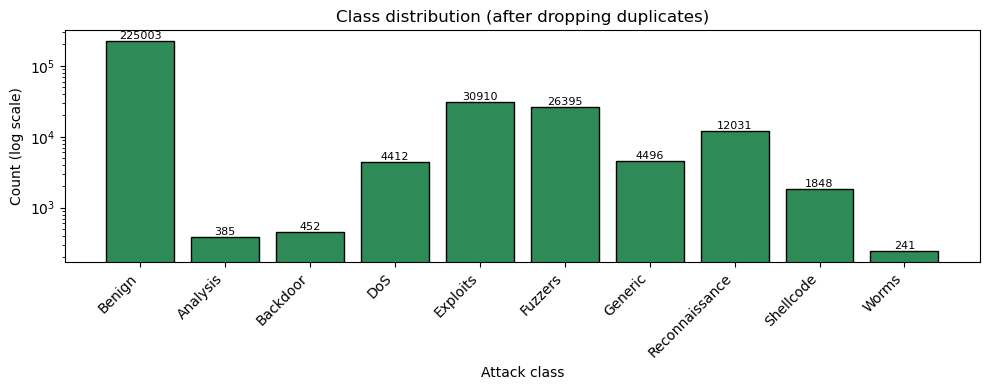

In [4]:
# Official label mapping (not stored in the CSVs). Attack families are alphabetical, Benign = 0.
LABELS = {
    0: "Benign", 1: "Analysis", 2: "Backdoor", 3: "DoS", 4: "Exploits",
    5: "Fuzzers", 6: "Generic", 7: "Reconnaissance", 8: "Shellcode", 9: "Worms",
}

counts = y["Label"].value_counts().sort_index()
dist = pd.DataFrame({
    "attack": [LABELS[i] for i in counts.index],
    "count": counts.values,
    "percent": (counts.values / counts.sum() * 100).round(3),
}, index=counts.index)
dist.index.name = "label"
print(dist)

# Log scale: with ~80% Benign vs ~0.05% rarest (Worms), a linear axis hides the rare classes.
plt.figure(figsize=(10, 4))
bars = plt.bar([LABELS[i] for i in counts.index], counts.values,
               color="seagreen", edgecolor="black")
plt.yscale("log")
plt.title("Class distribution (after dropping duplicates)")
plt.xlabel("Attack class")
plt.ylabel("Count (log scale)")
plt.xticks(rotation=45, ha="right")
plt.bar_label(bars, fontsize=8)
plt.tight_layout()
plt.show()

### 2.4 Variance check

A feature with only one unique value (zero variance) carries no information. Identify these constant columns; they become drop candidates in 2.6.

In [5]:
# A constant feature has exactly one unique value across all rows (zero variance).
nunique = X.nunique()
zero_var_cols = nunique[nunique <= 1].index.tolist()

print(f"Total features:           {X.shape[1]}")
print(f"Zero-variance (constant): {len(zero_var_cols)}\n")
for c in zero_var_cols:
    print(f"  {c:<22} -> constant value = {X[c].iloc[0]}")

Total features:           76
Zero-variance (constant): 9

  Bwd PSH Flags          -> constant value = 0
  Fwd URG Flags          -> constant value = 0
  Bwd URG Flags          -> constant value = 0
  URG Flag Count         -> constant value = 0
  CWR Flag Count         -> constant value = 0
  ECE Flag Count         -> constant value = 0
  Fwd Bytes/Bulk Avg     -> constant value = 0
  Fwd Packet/Bulk Avg    -> constant value = 0
  Fwd Bulk Rate Avg      -> constant value = 0


### 2.5 Correlation

Highly correlated features add redundancy without new signal. Plot the correlation matrix and list pairs above a threshold as drop candidates. The constant columns from 2.4 are excluded (their correlation is undefined).

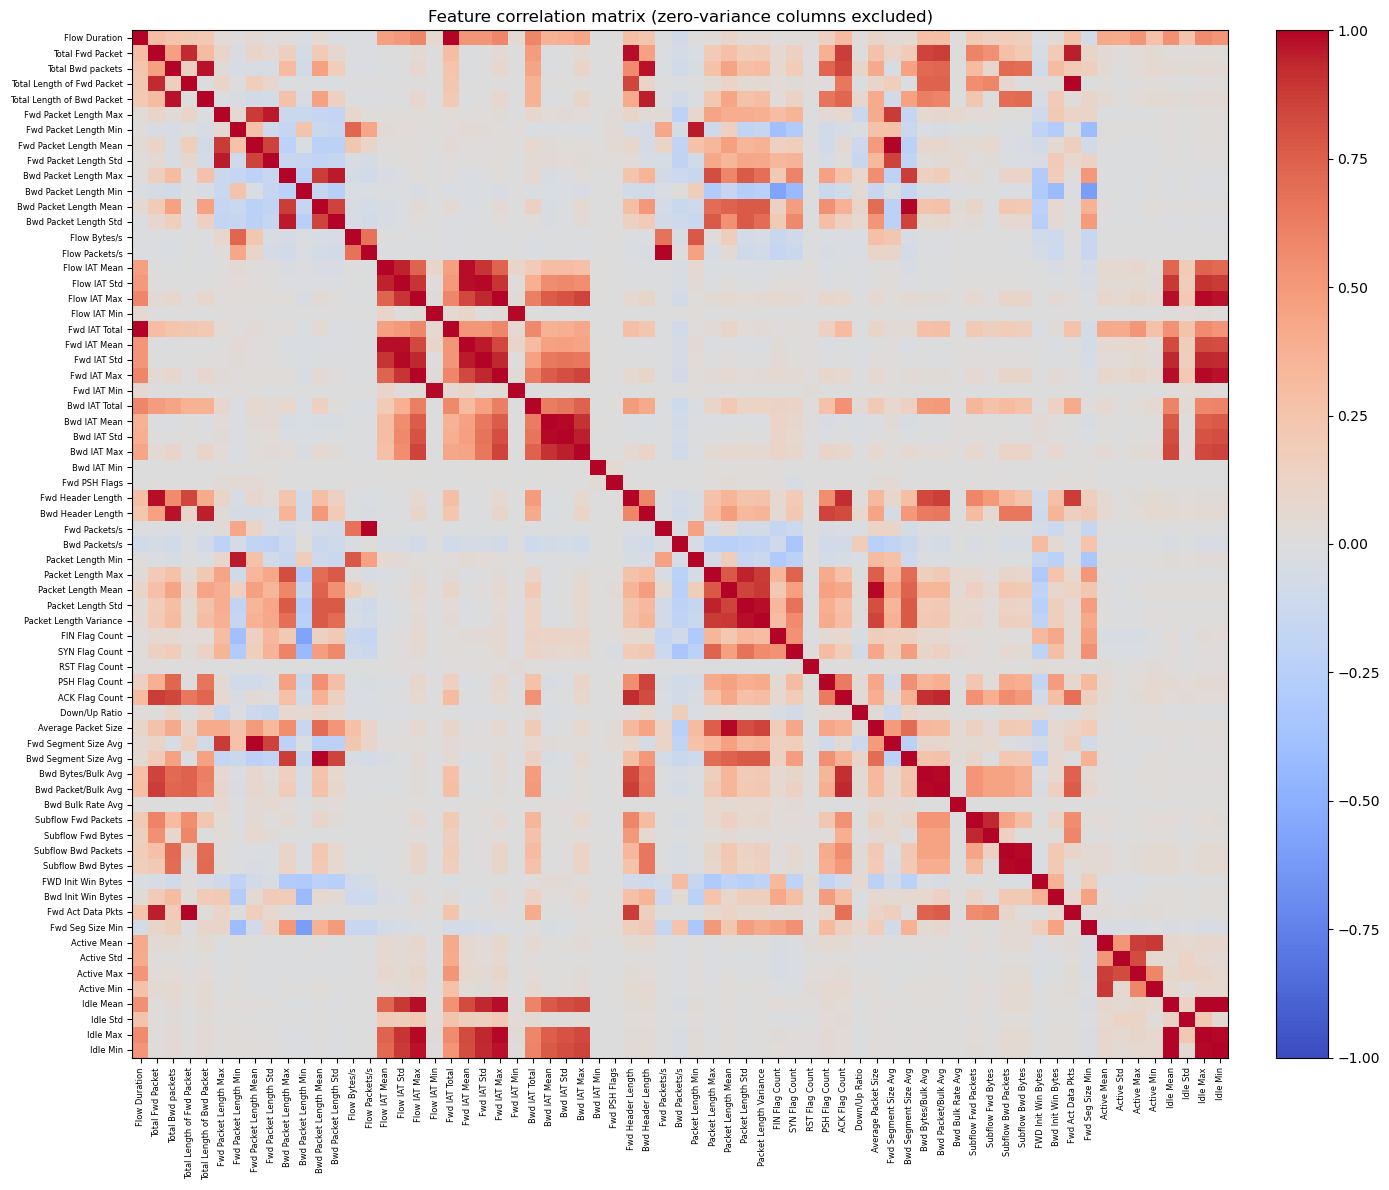

In [6]:
features = X.drop(columns=zero_var_cols)
corr = features.corr()

plt.figure(figsize=(14, 12))
im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.colorbar(im, fraction=0.046, pad=0.04)
plt.xticks(range(len(corr)), corr.columns, rotation=90, fontsize=6)
plt.yticks(range(len(corr)), corr.columns, fontsize=6)
plt.title("Feature correlation matrix (zero-variance columns excluded)")
plt.tight_layout()
plt.show()

In [7]:
# List highly correlated feature pairs (upper triangle only, to avoid duplicates).
THRESHOLD = 0.95

upper = corr.abs().where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
high_pairs = (
    upper.stack()
    .reset_index()
    .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "abs_corr"})
)
high_pairs = high_pairs[high_pairs["abs_corr"] >= THRESHOLD].sort_values(
    "abs_corr", ascending=False
).reset_index(drop=True)

print(f"Highly correlated pairs (|r| >= {THRESHOLD}): {len(high_pairs)}\n")
print(high_pairs.to_string(index=False))

Highly correlated pairs (|r| >= 0.95): 31

                 feature_1                  feature_2  abs_corr
    Fwd Packet Length Mean       Fwd Segment Size Avg  1.000000
    Bwd Packet Length Mean       Bwd Segment Size Avg  1.000000
            Flow Packets/s              Fwd Packets/s  0.999304
             Flow Duration              Fwd IAT Total  0.999037
              Flow IAT Max                Fwd IAT Max  0.997462
                 Idle Mean                   Idle Min  0.997389
                 Idle Mean                   Idle Max  0.995172
Total Length of Fwd Packet          Fwd Act Data Pkts  0.993241
        Packet Length Mean        Average Packet Size  0.991194
              Flow IAT Std                Fwd IAT Std  0.988993
        Bwd Bytes/Bulk Avg        Bwd Packet/Bulk Avg  0.988857
              Flow IAT Max                   Idle Max  0.988439
       Subflow Bwd Packets          Subflow Bwd Bytes  0.988309
                  Idle Max                   Idle Min  0.9863

### 2.6 Drop uninformative & redundant features

Act on the evidence: drop the **zero-variance** columns (2.4) and, for each highly-correlated pair (2.5), keep the first feature and drop the later one. The drop list is printed before applying.

In [8]:
# Redundant: a column is dropped if it correlates >= THRESHOLD with any earlier-kept column.
redundant_cols = [c for c in upper.columns if (upper[c] >= THRESHOLD).any()]

drop_cols = list(dict.fromkeys(zero_var_cols + redundant_cols))

print(f"Zero-variance to drop ({len(zero_var_cols)}):")
print(" ", zero_var_cols, "\n")
print(f"Redundant |r|>={THRESHOLD} to drop ({len(redundant_cols)}):")
print(" ", redundant_cols, "\n")
print(f"Total unique columns to drop: {len(drop_cols)}")

X = X.drop(columns=drop_cols)
print(f"\nFeatures remaining: {X.shape[1]} (from 76)")

Zero-variance to drop (9):
  ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count', 'Fwd Bytes/Bulk Avg', 'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg'] 

Redundant |r|>=0.95 to drop (23):
  ['Total Length of Bwd Packet', 'Fwd Packet Length Std', 'Bwd Packet Length Std', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Std', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Packet Length Min', 'Packet Length Variance', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg', 'Bwd Packet/Bulk Avg', 'Subflow Bwd Bytes', 'Fwd Act Data Pkts', 'Idle Mean', 'Idle Max', 'Idle Min'] 

Total unique columns to drop: 32

Features remaining: 44 (from 76)


### 2.7 Stratified train/test split

Split **before** any resampling so nothing leaks across train/test. `stratify=y` preserves each class's proportion in both splits. No scaling: Random Forest is scale-invariant.

In [9]:
from sklearn.model_selection import train_test_split

y_series = y["Label"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y_series,
    test_size=0.2,
    random_state=42,
    stratify=y_series,
)

print("Train:", X_train.shape, "| Test:", X_test.shape)

Train: (244938, 44) | Test: (61235, 44)


## 3. Model Selection
_Algorithm Choice_

**Random Forest** — an ensemble of decision trees, the strongest single-model baseline in the literature review and the base learner for the planned stacking ensemble. `class_weight='balanced'` is the same imbalance lever used for the Decision Tree, so the comparison isolates the model change.

In [10]:
from sklearn.ensemble import RandomForestClassifier

clf = RandomForestClassifier(
    n_estimators=200,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1,
)
clf

RandomForestClassifier(class_weight='balanced', n_estimators=200, n_jobs=-1,
                       random_state=42)

## 4. Model Training
_Learning Process_

Fit on the training split only. (200 trees on ~244K rows — may take a minute.)

In [11]:
clf.fit(X_train, y_train)
print("Training complete.")
print("Trees:", len(clf.estimators_))

Training complete.
Trees: 200


## 5. Model Evaluation
_Test Performance_

Same metrics as the Decision Tree baseline so the two are directly comparable. **Macro-F1** is the primary metric.

### 5.1 Metrics

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay,
)

y_pred  = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)   # class probabilities, needed for ROC-AUC

labels_sorted = sorted(y_test.unique())
target_names = [LABELS[i] for i in labels_sorted]

# 'weighted' = the "normal" average (each class weighted by its support, so dominated
# by Benign); 'macro' = every class counts equally, so rare attacks matter just as much.
roc_auc = roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro")
print(f"Accuracy    : {accuracy_score(y_test, y_pred):.4f}")
print(f"ROC-AUC     : {roc_auc:.4f}   (macro, One-vs-Rest)\n")

print(f"{'':<12}{'weighted':>10}{'macro':>10}")
for name, metric in [("Precision", precision_score), ("Recall", recall_score), ("F1-score", f1_score)]:
    w = metric(y_test, y_pred, average="weighted", zero_division=0)
    m = metric(y_test, y_pred, average="macro", zero_division=0)
    note = "   <- macro F1 = primary metric" if name == "F1-score" else ""
    print(f"{name:<12}{w:>10.4f}{m:>10.4f}{note}")

print()
print(classification_report(y_test, y_pred, target_names=target_names, digits=4))

Accuracy    : 0.9017
ROC-AUC     : 0.9401   (macro, One-vs-Rest)

              weighted     macro
Precision       0.9031    0.6521
Recall          0.9017    0.5358
F1-score        0.9004    0.5744   <- macro F1 = primary metric

                precision    recall  f1-score   support

        Benign     0.9849    0.9744    0.9796     45001
      Analysis     0.3443    0.2727    0.3043        77
      Backdoor     0.8654    0.5000    0.6338        90
           DoS     0.6319    0.2741    0.3823       883
      Exploits     0.7391    0.7892    0.7634      6182
       Fuzzers     0.6314    0.7670    0.6926      5279
       Generic     0.8400    0.7531    0.7941       899
Reconnaissance     0.6402    0.5769    0.6069      2406
     Shellcode     0.2440    0.1378    0.1762       370
         Worms     0.6000    0.3125    0.4110        48

      accuracy                         0.9017     61235
     macro avg     0.6521    0.5358    0.5744     61235
  weighted avg     0.9031    0.9017    0

### 5.2 Confusion matrix

Raw counts across the 10 classes (Benign-dominated). Per-class recall is reported numerically in 5.1.

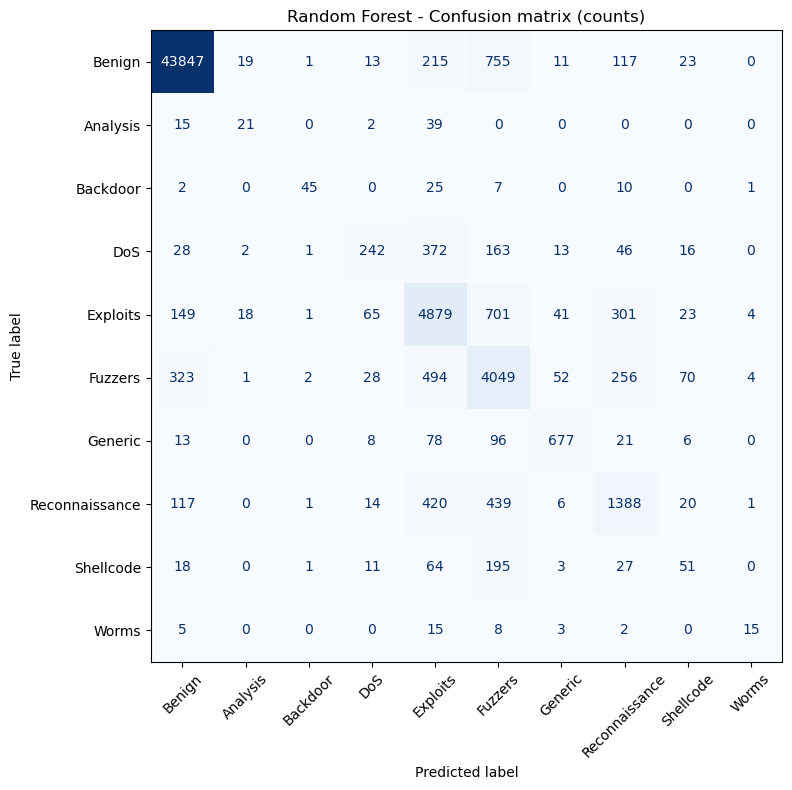

In [13]:
cm = confusion_matrix(y_test, y_pred, labels=labels_sorted)

fig, ax = plt.subplots(figsize=(9, 8))
ConfusionMatrixDisplay(cm, display_labels=target_names).plot(
    ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False
)
ax.set_title("Random Forest - Confusion matrix (counts)")
plt.tight_layout()
plt.show()